In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries working!")

Libraries working!


In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [7]:
df = pd.read_csv("IMDb Movies India.csv", encoding="cp1252")

In [8]:
df.head()

,Name,Year,Duration,Genre,Rating,Votes,Director,Actor 1,Actor 2,Actor 3
0,,NaN,NaN,Drama,NaN,NaN,J.S. Randhawa,Manmauji,Birbal,Rajendra Bhatia
1,#Gadhvi (He thought he was Gandhi),(2019),109 min,Drama,7.0,8,Gaurav Bakshi,Rasika Dugal,Vivek Ghamande,Arvind Jangid
2,#Homecoming,(2021),90 min,"Drama, Musical",NaN,NaN,Soumyajit Majumdar,Sayani Gupta,Plabita Borthakur,Roy Angana
3,#Yaaram,(2019),110 min,"Comedy, Romance",4.4,35,Ovais Khan,Prateik,Ishita Raj,Siddhant Kapoor
4,...And Once Again,(2010),105 min,Drama,NaN,NaN,Amol Palekar,Rajat Kapoor,Rituparna Sengupta,Antara Mali


In [9]:
df.shape

(15509, 10)

In [10]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 15509 entries, 0 to 15508
Data columns (total 10 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   Name      15509 non-null  str    
 1   Year      14981 non-null  str    
 2   Duration  7240 non-null   str    
 3   Genre     13632 non-null  str    
 4   Rating    7919 non-null   float64
 5   Votes     7920 non-null   str    
 6   Director  14984 non-null  str    
 7   Actor 1   13892 non-null  str    
 8   Actor 2   13125 non-null  str    
 9   Actor 3   12365 non-null  str    
dtypes: float64(1), str(9)
memory usage: 1.2 MB


In [11]:
df.isnull().sum()

Name           0
Year         528
Duration    8269
Genre       1877
Rating      7590
Votes       7589
Director     525
Actor 1     1617
Actor 2     2384
Actor 3     3144
dtype: int64

In [12]:
df.duplicated().sum()

np.int64(6)

In [13]:
df = df.drop_duplicates()

In [14]:
df.duplicated().sum()

np.int64(0)

In [15]:
df["Year"] = df["Year"].str.extract(r"(\d+)").astype(float)

In [16]:
df["Duration"].head()

0        NaN
1    109 min
2     90 min
3    110 min
4    105 min
Name: Duration, dtype: str

In [17]:
df["Votes"] = df["Votes"].str.replace(",", "", regex=False)
df["Votes"] = pd.to_numeric(df["Votes"], errors="coerce")

In [18]:
df["Votes"].head()

0     NaN
1     8.0
2     NaN
3    35.0
4     NaN
Name: Votes, dtype: float64

In [19]:
df.isnull().sum()

Name           0
Year         527
Duration    8264
Genre       1876
Rating      7584
Votes       7584
Director     524
Actor 1     1615
Actor 2     2381
Actor 3     3140
dtype: int64

In [20]:
df["Duration"] = df["Duration"].astype(str).str.extract(r"(\d+)")[0]
df["Duration"] = pd.to_numeric(df["Duration"], errors="coerce")

In [21]:
df["Duration"].dtype

dtype('float64')

In [22]:
df["Year"] = df["Year"].fillna(df["Year"].median())

df["Duration"] = df["Duration"].fillna(df["Duration"].median())

df["Votes"] = df["Votes"].fillna(df["Votes"].median())

In [23]:
df["Votes"] = df["Votes"].astype(str).str.replace(",", "", regex=False)
df["Votes"] = pd.to_numeric(df["Votes"], errors="coerce")

In [24]:
df["Votes"] = df["Votes"].fillna(df["Votes"].median())

In [25]:
df["Year"] = df["Year"].fillna(df["Year"].median())
df["Duration"] = df["Duration"].fillna(df["Duration"].median())
df["Votes"] = df["Votes"].fillna(df["Votes"].median())

In [26]:
df.info()

<class 'pandas.DataFrame'>
Index: 15503 entries, 0 to 15508
Data columns (total 10 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   Name      15503 non-null  str    
 1   Year      15503 non-null  float64
 2   Duration  15503 non-null  float64
 3   Genre     13627 non-null  str    
 4   Rating    7919 non-null   float64
 5   Votes     15503 non-null  float64
 6   Director  14979 non-null  str    
 7   Actor 1   13888 non-null  str    
 8   Actor 2   13122 non-null  str    
 9   Actor 3   12363 non-null  str    
dtypes: float64(4), str(6)
memory usage: 1.3 MB


In [27]:
df = df.dropna(subset=["Rating"])

In [28]:
text_columns = ["Genre", "Director", "Actor 1", "Actor 2", "Actor 3"]

for column in text_columns:
    df[column] = df[column].fillna("Unknown")

In [29]:
df.isnull().sum()

Name        0
Year        0
Duration    0
Genre       0
Rating      0
Votes       0
Director    0
Actor 1     0
Actor 2     0
Actor 3     0
dtype: int64

In [30]:
df.shape

(7919, 10)

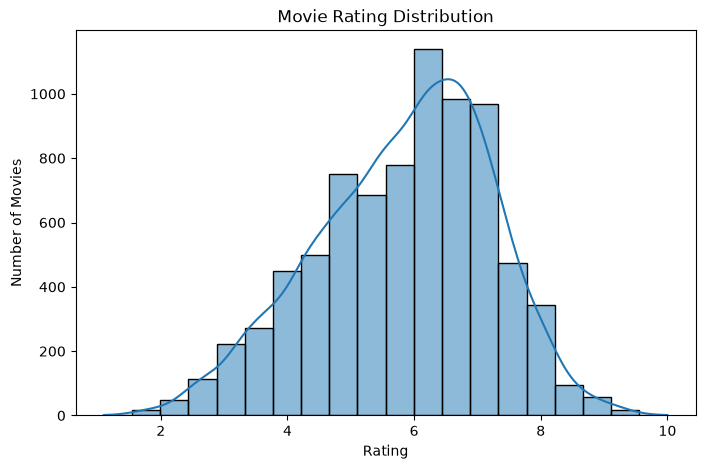

In [31]:
plt.figure(figsize=(8, 5))

sns.histplot(df["Rating"], bins=20, kde=True)

plt.title("Movie Rating Distribution")
plt.xlabel("Rating")
plt.ylabel("Number of Movies")

plt.show()

In [32]:
df["Rating"].describe()

count    7919.000000
mean        5.841621
std         1.381777
min         1.100000
25%         4.900000
50%         6.000000
75%         6.800000
max        10.000000
Name: Rating, dtype: float64

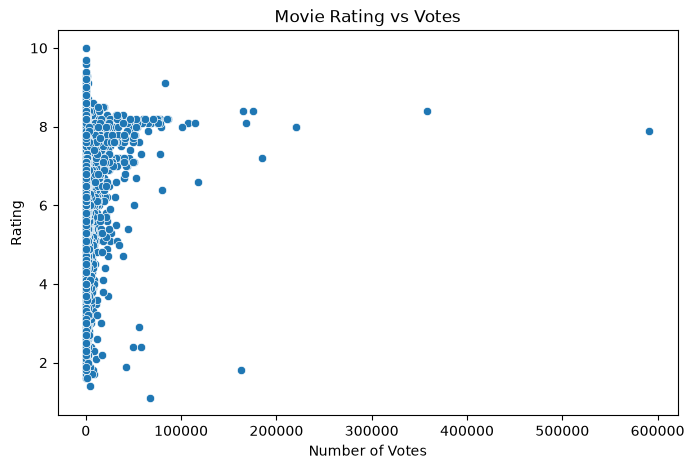

In [33]:
plt.figure(figsize=(8, 5))

sns.scatterplot(data=df, x="Votes", y="Rating")

plt.title("Movie Rating vs Votes")
plt.xlabel("Number of Votes")
plt.ylabel("Rating")

plt.show()

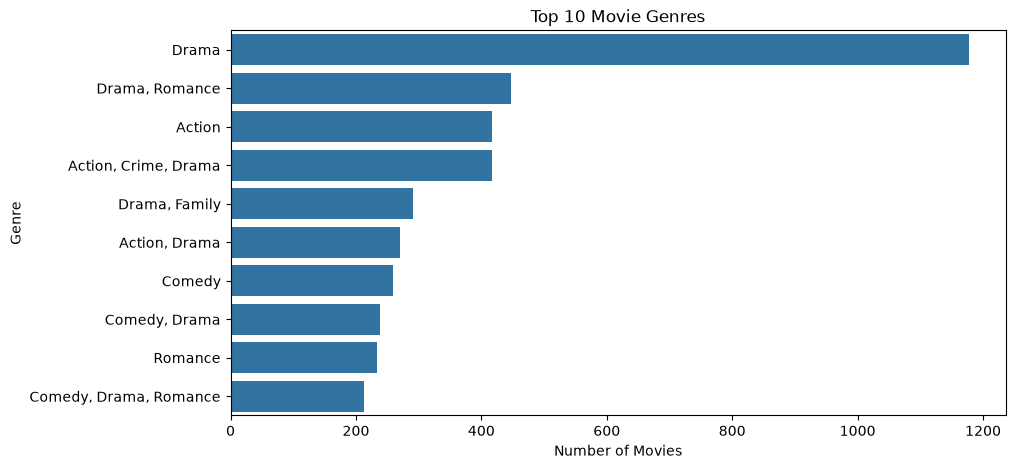

In [34]:
genre_counts = df["Genre"].value_counts().head(10)

plt.figure(figsize=(10, 5))

sns.barplot(x=genre_counts.values, y=genre_counts.index)

plt.title("Top 10 Movie Genres")
plt.xlabel("Number of Movies")
plt.ylabel("Genre")

plt.show()

In [35]:
df["Rating"].describe()

count    7919.000000
mean        5.841621
std         1.381777
min         1.100000
25%         4.900000
50%         6.000000
75%         6.800000
max        10.000000
Name: Rating, dtype: float64

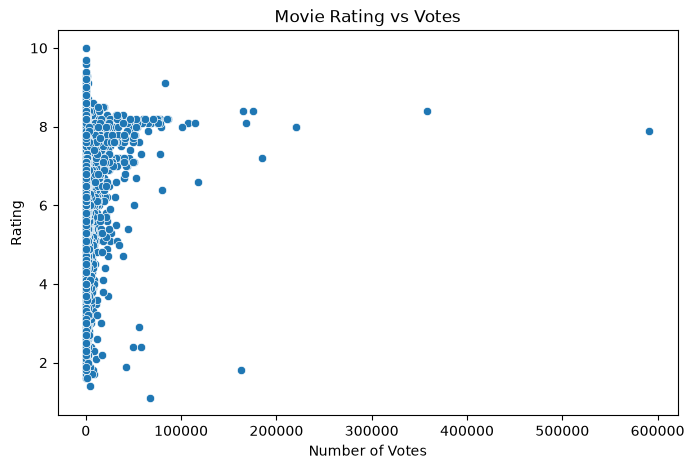

In [36]:
plt.figure(figsize=(8, 5))

sns.scatterplot(data=df, x="Votes", y="Rating")

plt.title("Movie Rating vs Votes")
plt.xlabel("Number of Votes")
plt.ylabel("Rating")

plt.show()

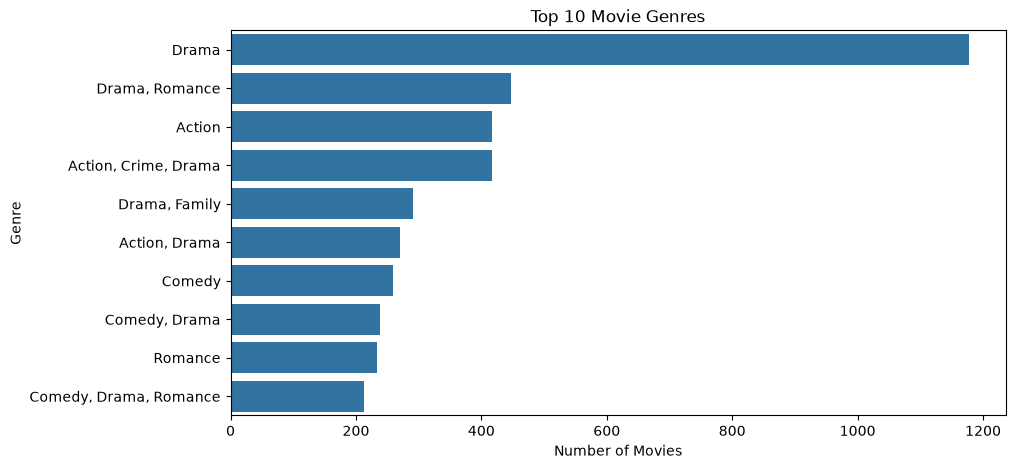

In [37]:
genre_counts = df["Genre"].value_counts().head(10)

plt.figure(figsize=(10, 5))

sns.barplot(x=genre_counts.values, y=genre_counts.index)

plt.title("Top 10 Movie Genres")
plt.xlabel("Number of Movies")
plt.ylabel("Genre")

plt.show()

In [38]:
X = df[
    [
        "Year",
        "Duration",
        "Votes",
        "Genre",
        "Director",
        "Actor 1",
        "Actor 2",
        "Actor 3"
    ]
]

In [39]:
y = df["Rating"]

In [40]:
print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (7919, 8)
Target shape: (7919,)


In [41]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

In [42]:
print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (6335, 8)
Testing data: (1584, 8)


In [43]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

In [44]:
categorical_features = [
    "Genre",
    "Director",
    "Actor 1",
    "Actor 2",
    "Actor 3"
]

In [45]:
numeric_features = [
    "Year",
    "Duration",
    "Votes"
]

In [46]:
preprocessor = ColumnTransformer(
    transformers=[
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features),
        ("num", "passthrough", numeric_features)
    ]
)

In [47]:
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import Pipeline

model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("regressor", LinearRegression())
    ]
)

In [48]:
model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('regressor', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](8,)","['Year','Duration','Votes',...,'Actor 1','Actor 2','Actor 3']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,8
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('cat', ...), ('num', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis conca

In [49]:
y_pred = model.predict(X_test)

In [50]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print("MAE:", mae)
print("RMSE:", rmse)
print("R2 Score:", r2)

MAE: 0.9436032664560215
RMSE: 1.205058128260297
R2 Score: 0.21890708759600674


In [51]:
from sklearn.ensemble import RandomForestRegressor

rf_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("regressor", RandomForestRegressor(
            n_estimators=100,
            random_state=42,
            n_jobs=-1
        ))
    ]
)

In [52]:
rf_model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('regressor', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](8,)","['Year','Duration','Votes',...,'Actor 1','Actor 2','Actor 3']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,8
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('cat', ...), ('num', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis conca

In [53]:
rf_pred = rf_model.predict(X_test)

In [54]:
rf_mae = mean_absolute_error(y_test, rf_pred)
rf_rmse = np.sqrt(mean_squared_error(y_test, rf_pred))
rf_r2 = r2_score(y_test, rf_pred)

print("Random Forest MAE:", rf_mae)
print("Random Forest RMSE:", rf_rmse)
print("Random Forest R2 Score:", rf_r2)

Random Forest MAE: 0.8011104797979797
Random Forest RMSE: 1.0794833702243445
Random Forest R2 Score: 0.373214967935114


In [55]:
print("Linear Regression")
print("MAE:", mae)
print("RMSE:", rmse)
print("R2 Score:", r2)

print("\nRandom Forest")
print("MAE:", rf_mae)
print("RMSE:", rf_rmse)
print("R2 Score:", rf_r2)

Linear Regression
MAE: 0.9436032664560215
RMSE: 1.205058128260297
R2 Score: 0.21890708759600674

Random Forest
MAE: 0.8011104797979797
RMSE: 1.0794833702243445
R2 Score: 0.373214967935114


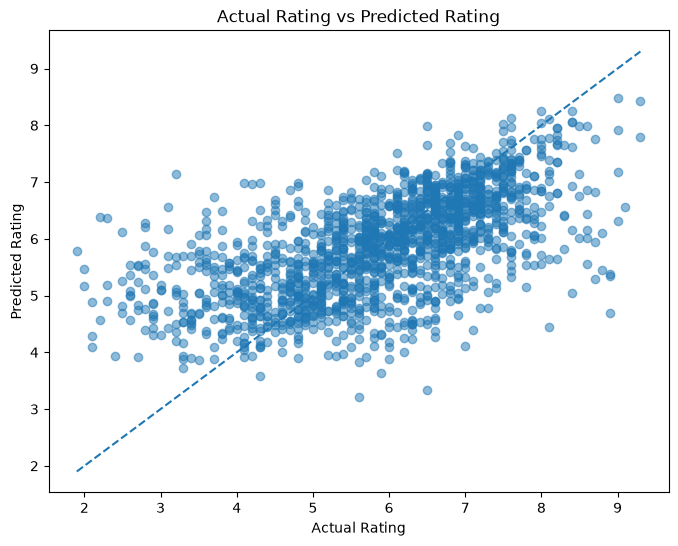

In [56]:
plt.figure(figsize=(8, 6))

plt.scatter(y_test, rf_pred, alpha=0.5)

plt.xlabel("Actual Rating")
plt.ylabel("Predicted Rating")
plt.title("Actual Rating vs Predicted Rating")

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    linestyle="--"
)

plt.show()

In [57]:
comparison = pd.DataFrame({
    "Actual Rating": y_test.values,
    "Predicted Rating": rf_pred
})

comparison.head(10)

,Actual Rating,Predicted Rating
0,3.3,3.732
1,5.3,5.308
2,5.7,5.991
3,7.2,6.614
4,3.5,5.780
5,7.2,6.517
6,3.8,5.138
7,6.9,6.846
8,5.2,5.700
9,7.4,6.371


In [58]:
new_movie = pd.DataFrame({
    "Year": [2025],
    "Duration": [120],
    "Votes": [5000],
    "Genre": ["Drama"],
    "Director": ["Unknown"],
    "Actor 1": ["Unknown"],
    "Actor 2": ["Unknown"],
    "Actor 3": ["Unknown"]
})

predicted_rating = rf_model.predict(new_movie)

print("Predicted Movie Rating:", predicted_rating[0])

Predicted Movie Rating: 6.871000000000002


In [59]:
results = pd.DataFrame({
    "Model": ["Linear Regression", "Random Forest"],
    "MAE": [mae, rf_mae],
    "RMSE": [rmse, rf_rmse],
    "R2 Score": [r2, rf_r2]
})

results

,Model,MAE,RMSE,R2 Score
0,Linear Regression,0.943603,1.205058,0.218907
1,Random Forest,0.801110,1.079483,0.373215


In [60]:
import pandas as pd
import numpy as np

In [61]:
results = pd.DataFrame({
    "Model": ["Linear Regression", "Random Forest"],
    "MAE": [mae, rf_mae],
    "RMSE": [rmse, rf_rmse],
    "R2 Score": [r2, rf_r2]
})

results

,Model,MAE,RMSE,R2 Score
0,Linear Regression,0.943603,1.205058,0.218907
1,Random Forest,0.801110,1.079483,0.373215


In [62]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Linear Regression metrics
y_pred = model.predict(X_test)

mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

# Random Forest metrics
rf_pred = rf_model.predict(X_test)

rf_mae = mean_absolute_error(y_test, rf_pred)
rf_rmse = np.sqrt(mean_squared_error(y_test, rf_pred))
rf_r2 = r2_score(y_test, rf_pred)

print("Metrics calculated successfully!")

Metrics calculated successfully!


In [63]:
results = pd.DataFrame({
    "Model": ["Linear Regression", "Random Forest"],
    "MAE": [mae, rf_mae],
    "RMSE": [rmse, rf_rmse],
    "R2 Score": [r2, rf_r2]
})

results

,Model,MAE,RMSE,R2 Score
0,Linear Regression,0.943603,1.205058,0.218907
1,Random Forest,0.801110,1.079483,0.373215


In [64]:
best_model_name = results.sort_values(
    by="MAE",
    ascending=True
).iloc[0]["Model"]

print("Best Model:", best_model_name)

Best Model: Random Forest


Conclusion

The Movie Rating Prediction project was developed using Python and the IMDb India Movies dataset.

Data cleaning was performed to handle missing values and convert numerical features into suitable formats. Exploratory Data Analysis (EDA) was carried out to understand movie ratings, votes, and genres.

Two machine learning regression models, Linear Regression and Random Forest Regressor, were trained and evaluated using MAE, RMSE, and R² Score.

The models were compared to identify which model performed better. The project demonstrates how machine learning techniques can predict movie ratings based on features such as year, duration, votes, genre, director, and actors.

Overall, this project provided practical experience in data preprocessing, data visualization, model training, and model evaluation using Python.